In [1]:
X = [
    [2, 3],
    [3, 3],
    [3, 4],
    [4, 3],
    [6, 6],
    [7, 7],
    [8, 6],
    [7, 8]
]

y = [-1, -1, -1, -1, 1, 1, 1, 1]

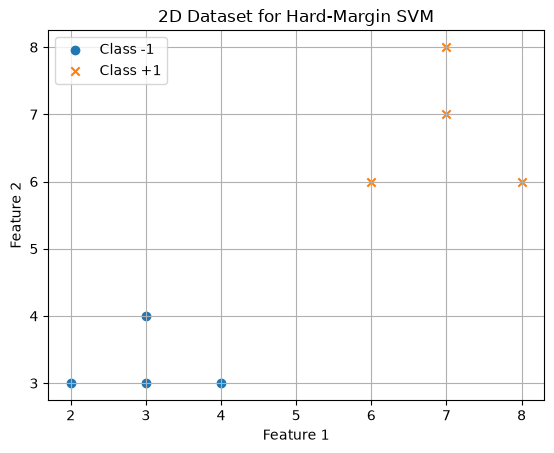

In [3]:
import matplotlib.pyplot as plt

class1_x = []
class1_y = []
class2_x = []
class2_y = []

for i in range(len(X)):
    if y[i] == -1:
        class1_x.append(X[i][0])
        class1_y.append(X[i][1])
    else:
        class2_x.append(X[i][0])
        class2_y.append(X[i][1])

# Plot the points
plt.scatter(class1_x, class1_y, label="Class -1", marker="o")
plt.scatter(class2_x, class2_y, label="Class +1", marker="x")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("2D Dataset for Hard-Margin SVM")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
def dot_product(a, b):
    total = 0

    for i in range(len(a)):
        total += a[i] * b[i]

    return total

In [5]:
a = [2, 3]
b = [4, 5]

print(dot_product(a, b))  # 23

23


In [6]:
def decision_score(x, w, b):
    return dot_product(w, x) + b

In [7]:
w = [2, 1]
b = -10
x = [3, 4]

score = decision_score(x, w, b)
print(score)

0


Score >0: predict class +1.

Score <0: predict class -1.

Score =0: point lies on the boundary.

In [8]:
n = len(X)
alphas = [0.0] * n
b = 0.0

In [9]:
def calculate_w(X, y, alphas):
    n_features = len(X[0])
    w = [0.0] * n_features

    for i in range(len(X)):
        for j in range(n_features):
            w[j] += alphas[i] * y[i] * X[i][j]

    return w

In [10]:
alphas = [0.0] * len(X)

w = calculate_w(X, y, alphas)
print(w)

[0.0, 0.0]


In [11]:
alphas = [0.1, 0.2, 0, 0, 0, 0, 0, 0]

w = calculate_w(X, y, alphas)
print(w)

[-0.8, -0.9000000000000001]


In [12]:
alphas = [0.1, 0.2, 0, 0, 0, 0, 0, 0]

w = calculate_w(X, y, alphas)
b = 0.0

for i in range(len(X)):
    score = decision_score(X[i], w, b)
    print("Point:", X[i],
          "Actual:", y[i],
          "Score:", round(score, 2))

Point: [2, 3] Actual: -1 Score: -4.3
Point: [3, 3] Actual: -1 Score: -5.1
Point: [3, 4] Actual: -1 Score: -6.0
Point: [4, 3] Actual: -1 Score: -5.9
Point: [6, 6] Actual: 1 Score: -10.2
Point: [7, 7] Actual: 1 Score: -11.9
Point: [8, 6] Actual: 1 Score: -11.8
Point: [7, 8] Actual: 1 Score: -12.8


In [13]:
def create_dot_product_matrix(X):
    n = len(X)
    matrix = []

    for i in range(n):
        row = []

        for j in range(n):
            value = dot_product(X[i], X[j])
            row.append(value)

        matrix.append(row)

    return matrix

In [14]:
dot_matrix = create_dot_product_matrix(X)

for row in dot_matrix:
    print(row)

[13, 15, 18, 17, 30, 35, 34, 38]
[15, 18, 21, 21, 36, 42, 42, 45]
[18, 21, 25, 24, 42, 49, 48, 53]
[17, 21, 24, 25, 42, 49, 50, 52]
[30, 36, 42, 42, 72, 84, 84, 90]
[35, 42, 49, 49, 84, 98, 98, 105]
[34, 42, 48, 50, 84, 98, 100, 104]
[38, 45, 53, 52, 90, 105, 104, 113]


In [15]:
def calculate_score(i, X, y, alphas, b, dot_matrix):
    score = b

    for j in range(len(X)):
        score += (
            alphas[j]
            * y[j]
            * dot_matrix[j][i]
        )

    return score

In [16]:
alphas = [0.1, 0.2, 0, 0, 0, 0, 0, 0]
b = 0.0

for i in range(len(X)):
    score = calculate_score(
        i, X, y, alphas, b, dot_matrix
    )
    print("Point:", X[i], "Score:", round(score, 2))

Point: [2, 3] Score: -4.3
Point: [3, 3] Score: -5.1
Point: [3, 4] Score: -6.0
Point: [4, 3] Score: -5.9
Point: [6, 6] Score: -10.2
Point: [7, 7] Score: -11.9
Point: [8, 6] Score: -11.8
Point: [7, 8] Score: -12.8


In [ ]:

def calculate_bounds(alpha1, alpha2, y1, y2):
    if y1 != y2:
        L = max(0, alpha2 - alpha1)
        H = float("inf")
    else:
        L = 0
        H = alpha1 + alpha2

    return L, H

In [20]:
alpha1 = 0.1
alpha2 = 0.2

L, H = calculate_bounds(alpha1, alpha2, -1, -1)

print("Lower bound:", L)
print("Upper bound:", H)

Lower bound: 0
Upper bound: 0.30000000000000004


In [21]:

def calculate_error(i, X, y, alphas, b, dot_matrix):
    score = calculate_score(i, X, y, alphas, b, dot_matrix)
    error = score - y[i]
    return error


In [22]:

b = 0.0

error = calculate_error(
    0, X, y, alphas, b, dot_matrix
)

print("Prediction error:", error)


Prediction error: -3.3


In [23]:

def calculate_eta(dot_matrix, i, j):
    return (
        dot_matrix[i][i]
        + dot_matrix[j][j]
        - 2 * dot_matrix[i][j]
    )

eta = calculate_eta(dot_matrix, 0, 1)
print("Eta:", eta)


Eta: 1


In [26]:

def calculate_new_alpha2(alpha2, y2, E1, E2, eta):
    if eta <= 0:
        return None

    return alpha2 - (y2 * (E1 - E2)) / eta


In [27]:

E1 = calculate_error(0, X, y, alphas, b, dot_matrix)
E2 = calculate_error(1, X, y, alphas, b, dot_matrix)

eta = calculate_eta(dot_matrix, 0, 1)

proposed_alpha2 = calculate_new_alpha2(
    alphas[1], y[1], E1, E2, eta
)

print("E1:", E1)
print("E2:", E2)
print("Eta:", eta)
print("Proposed alpha2:", proposed_alpha2)


E1: -3.3
E2: -4.1
Eta: 1
Proposed alpha2: 0.9999999999999998


In [29]:

alpha1 = alphas[0]
alpha2 = alphas[1]

y1 = y[0]
y2 = y[1]

L, H = calculate_bounds(alpha1, alpha2, y1, y2)

new_alpha2 = clip_alpha(proposed_alpha2, L, H)

print("Lower bound:", L)
print("Upper bound:", H)
print("Clipped alpha2:", new_alpha2)


Lower bound: 0
Upper bound: 0.30000000000000004
Clipped alpha2: 0.30000000000000004


In [30]:

new_alpha1 = alpha1 + alpha2 - new_alpha2

print("New alpha1:", new_alpha1)
print("New alpha2:", new_alpha2)

print("Constraint check:",
      new_alpha1 * y1 + new_alpha2 * y2)


New alpha1: 0.0
New alpha2: 0.30000000000000004
Constraint check: -0.30000000000000004


In [31]:
alphas[0] = new_alpha1
alphas[1] = new_alpha2

print("Updated alphas:", alphas)

Updated alphas: [0.0, 0.30000000000000004, 0, 0, 0, 0, 0, 0]


In [32]:

E1 = calculate_error(0, X, y, alphas, b, dot_matrix)
E2 = calculate_error(1, X, y, alphas, b, dot_matrix)

print("Updated E1:", E1)
print("Updated E2:", E2)


Updated E1: -3.500000000000001
Updated E2: -4.4


In [33]:

def satisfies_margin(i, X, y, alphas, b, dot_matrix):
    score = calculate_score(i, X, y, alphas, b, dot_matrix)
    return y[i] * score >= 1


In [34]:

result = satisfies_margin(0, X, y, alphas, b, dot_matrix)
print("First point satisfies margin:", result)


First point satisfies margin: True


In [35]:

for i in range(len(X)):
    score = calculate_score(i, X, y, alphas, b, dot_matrix)
    margin = y[i] * score

    print(
        "Point:", i + 1,
        "| Score:", round(score, 2),
        "| Margin:", round(margin, 2),
        "| Satisfies margin:", margin >= 1
    )


Point: 1 | Score: -4.5 | Margin: 4.5 | Satisfies margin: True
Point: 2 | Score: -5.4 | Margin: 5.4 | Satisfies margin: True
Point: 3 | Score: -6.3 | Margin: 6.3 | Satisfies margin: True
Point: 4 | Score: -6.3 | Margin: 6.3 | Satisfies margin: True
Point: 5 | Score: -10.8 | Margin: -10.8 | Satisfies margin: False
Point: 6 | Score: -12.6 | Margin: -12.6 | Satisfies margin: False
Point: 7 | Score: -12.6 | Margin: -12.6 | Satisfies margin: False
Point: 8 | Score: -13.5 | Margin: -13.5 | Satisfies margin: False


In [36]:

def smo_pair_update(i, j, X, y, alphas, b, dot_matrix):
    # Save the old alpha values
    alpha1_old = alphas[i]
    alpha2_old = alphas[j]

    y1 = y[i]
    y2 = y[j]

    # Calculate prediction errors using the old model
    E1 = calculate_error(i, X, y, alphas, b, dot_matrix)
    E2 = calculate_error(j, X, y, alphas, b, dot_matrix)

    # Calculate eta
    eta = calculate_eta(dot_matrix, i, j)

    # This update formula requires positive eta
    if eta <= 1e-12:
        return b, False

    # Calculate valid bounds for the new alpha2
    L, H = calculate_bounds(
        alpha1_old, alpha2_old, y1, y2
    )

    # Propose the new alpha2
    alpha2_new = (
        alpha2_old - y2 * (E1 - E2) / eta
    )

    # Clip alpha2 to its valid bounds
    alpha2_new = clip_alpha(alpha2_new, L, H)

    # Skip negligible changes
    if abs(alpha2_new - alpha2_old) < 1e-8:
        return b, False

    # Calculate alpha1 to preserve the equality constraint
    alpha1_new = (
        alpha1_old
        + y1 * y2 * (alpha2_old - alpha2_new)
    )

    # Calculate the new bias
    delta1 = alpha1_new - alpha1_old
    delta2 = alpha2_new - alpha2_old

    b1 = (
        b - E1
        - y1 * delta1 * dot_matrix[i][i]
        - y2 * delta2 * dot_matrix[i][j]
    )

    b2 = (
        b - E2
        - y1 * delta1 * dot_matrix[i][j]
        - y2 * delta2 * dot_matrix[j][j]
    )

    # In hard-margin SVM, positive alphas identify
    # support vectors
    if alpha1_new > 1e-8:
        new_b = b1
    elif alpha2_new > 1e-8:
        new_b = b2
    else:
        new_b = (b1 + b2) / 2

    # Store both updated alpha values
    alphas[i] = alpha1_new
    alphas[j] = alpha2_new

    return new_b, True


In [37]:

b = 0.0

b, changed = smo_pair_update(
    0, 1, X, y, alphas, b, dot_matrix
)

print("Updated alphas:", alphas)
print("Updated bias:", b)
print("Pair updated:", changed)


Updated alphas: [0.0, 0.30000000000000004, 0, 0, 0, 0, 0, 0]
Updated bias: 0.0
Pair updated: False


In [38]:

def train_svm(X, y, alphas, b, dot_matrix, epochs=100):
    n = len(X)

    for epoch in range(epochs):
        changes = 0

        for i in range(n):
            for j in range(i + 1, n):
                b, changed = smo_pair_update(
                    i, j, X, y, alphas, b, dot_matrix
                )

                if changed:
                    changes += 1

        print(
            "Epoch:", epoch + 1,
            "| Pair updates:", changes
        )

        if changes == 0:
            print("No further pair updates.")
            break

    return alphas, b


In [39]:

alphas = [0.0] * len(X)
b = 0.0

alphas, b = train_svm(
    X, y, alphas, b, dot_matrix, epochs=100
)

print("Final alphas:", alphas)
print("Final bias:", b)


Epoch: 1 | Pair updates: 0
No further pair updates.
Final alphas: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Final bias: 0.0


In [40]:

alphas = [0.0] * len(X)
b = 0.0

E1 = calculate_error(0, X, y, alphas, b, dot_matrix)
E2 = calculate_error(1, X, y, alphas, b, dot_matrix)
eta = calculate_eta(dot_matrix, 0, 1)

print("E1:", E1)
print("E2:", E2)
print("Eta:", eta)
print("Proposed alpha2:",
      alphas[1] - y[1] * (E1 - E2) / eta)


E1: 1.0
E2: 1.0
Eta: 1
Proposed alpha2: 0.0


In [41]:

def find_violating_points(X, y, alphas, b, dot_matrix):
    violating = []

    for i in range(len(X)):
        score = calculate_score(
            i, X, y, alphas, b, dot_matrix
        )

        margin = y[i] * score

        if margin < 1 - 1e-8:
            violating.append(i)

    return violating


alphas = [0.0] * len(X)
b = 0.0

violating = find_violating_points(
    X, y, alphas, b, dot_matrix
)

print("Violating point indices:", violating)



Violating point indices: [0, 1, 2, 3, 4, 5, 6, 7]


Training iterations: 38
Weight vector: [1.99999887e+00 4.53979747e-07]
Bias: -6.999997276121535

Hyperplane equation:
2.0000*x1 + 0.0000*x2 + (-7.0000) = 0
Total margin width: 1.0000005674749777

Support vectors:
Point: [3.  1.5], Class: -1, Alpha: 1.999999
Point: [4. 4.], Class: 1, Alpha: 0.333333
Point: [4. 1.], Class: 1, Alpha: 1.666666

Minimum functional margin: 0.9999986380607595
All points satisfy margin >= 1: True


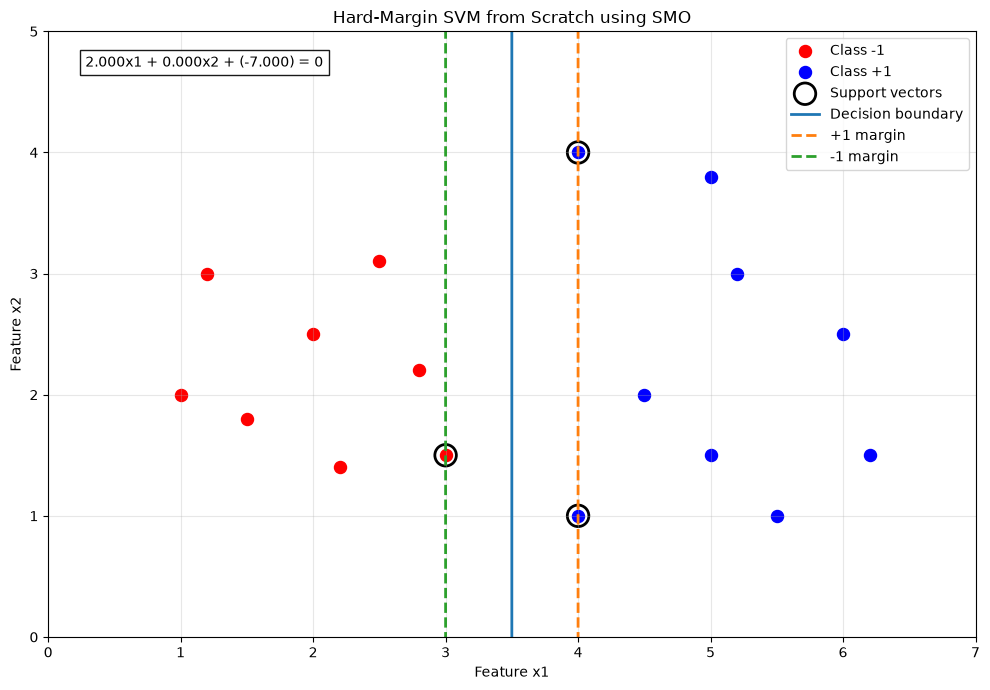

In [42]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: Create 17 linearly separable points
# ==========================================

X = np.array([
    [1.0, 2.0],
    [1.5, 1.8],
    [2.0, 2.5],
    [2.2, 1.4],
    [2.8, 2.2],
    [3.0, 1.5],
    [1.2, 3.0],
    [2.5, 3.1],

    [4.0, 4.0],
    [4.0, 1.0],
    [4.5, 2.0],
    [5.0, 1.5],
    [5.2, 3.0],
    [5.5, 1.0],
    [6.0, 2.5],
    [6.2, 1.5],
    [5.0, 3.8]
])

y = np.array([-1.0] * 8 + [1.0] * 9)

# ==========================================
# STEP 2: Implement hard-margin SMO
# ==========================================

def hard_margin_smo(X, y, tol=1e-5,
                    alpha_eps=1e-8,
                    max_passes=30,
                    max_iter=100000):

    n = len(X)

    # Linear kernel: K(i,j) = Xi dot Xj
    K = X @ X.T

    # Start with all alpha values and bias equal to zero
    alpha = np.zeros(n)
    b = 0.0

    # Calculate prediction errors
    def get_errors():
        return (alpha * y) @ K + b - y

    passes = 0
    iterations = 0

    while passes < max_passes and iterations < max_iter:

        changed = 0
        E = get_errors()

        for i in range(n):

            Ei = E[i]

            # Check whether point i violates KKT conditions
            r = y[i] * Ei

            if not (r < -tol or
                    (r > tol and alpha[i] > alpha_eps)):
                continue

            # Try the point with the largest error difference first
            candidates = [j for j in range(n) if j != i]
            candidates.sort(
                key=lambda j: abs(Ei - E[j]),
                reverse=True
            )

            for j in candidates:

                Ej = E[j]

                ai_old = alpha[i]
                aj_old = alpha[j]

                # Find feasible limits for alpha[j]
                if y[i] != y[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = float("inf")
                else:
                    L = 0.0
                    H = ai_old + aj_old

                if H - L < 1e-12:
                    continue

                # Curvature of the dual objective
                eta = K[i, i] + K[j, j] - 2 * K[i, j]

                if eta <= 1e-12:
                    continue

                # Update alpha[j]
                aj_new = aj_old + y[j] * (Ei - Ej) / eta

                # Clip alpha[j] to its feasible range
                aj_new = max(L, min(H, aj_new))

                if abs(aj_new - aj_old) < 1e-8:
                    continue

                # Update alpha[i] to preserve the equality constraint
                ai_new = (
                    ai_old
                    + y[i] * y[j] * (aj_old - aj_new)
                )

                # Calculate two candidate bias values
                b1 = (
                    b - Ei
                    - y[i] * (ai_new - ai_old) * K[i, i]
                    - y[j] * (aj_new - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (ai_new - ai_old) * K[i, j]
                    - y[j] * (aj_new - aj_old) * K[j, j]
                )

                # Select the appropriate bias
                if ai_new > alpha_eps:
                    b = b1
                elif aj_new > alpha_eps:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                # Save updated alpha values
                alpha[i] = max(0.0, ai_new)
                alpha[j] = max(0.0, aj_new)

                changed += 1

                # Recalculate errors after the update
                E = get_errors()

                # Move to the next i
                break

        iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    # Recover w from the learned alpha values
    w = (alpha * y) @ X

    return w, b, alpha, iterations


# ==========================================
# STEP 3: Train the model
# ==========================================

w, b, alpha, iterations = hard_margin_smo(X, y)

print("Training iterations:", iterations)
print("Weight vector:", w)
print("Bias:", b)

print("\nHyperplane equation:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + ({b:.4f}) = 0")

margin_width = 2 / np.linalg.norm(w)
print("Total margin width:", margin_width)

# ==========================================
# STEP 4: Find support vectors
# ==========================================

support_mask = alpha > 1e-5

print("\nSupport vectors:")
for i in range(len(X)):
    if support_mask[i]:
        print(
            f"Point: {X[i]}, "
            f"Class: {int(y[i])}, "
            f"Alpha: {alpha[i]:.6f}"
        )

# Check the hard-margin constraints
functional_margin = y * (X @ w + b)

print("\nMinimum functional margin:",
      np.min(functional_margin))

print("All points satisfy margin >= 1:",
      np.all(functional_margin >= 1 - 1e-4))

# ==========================================
# STEP 5: Plot the learned hyperplane
# ==========================================

plt.figure(figsize=(10, 7))

plt.scatter(
    X[y == -1, 0], X[y == -1, 1],
    color="red", s=75, label="Class -1"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", s=75, label="Class +1"
)

# Circle the learned support vectors
plt.scatter(
    X[support_mask, 0],
    X[support_mask, 1],
    s=240, facecolors="none",
    edgecolors="black", linewidths=2,
    label="Support vectors"
)

# Draw w.x + b = c
x_line = np.linspace(0, 7, 300)

for c, style, label in [
    (0, "-", "Decision boundary"),
    (1, "--", "+1 margin"),
    (-1, "--", "-1 margin")
]:

    if abs(w[1]) > 1e-8:
        y_line = (c - b - w[0] * x_line) / w[1]
        plt.plot(
            x_line, y_line,
            linestyle=style, linewidth=2,
            label=label
        )
    else:
        x_value = (c - b) / w[0]
        plt.axvline(
            x_value, linestyle=style,
            linewidth=2, label=label
        )

# Write the actual learned equation on the plot
equation = (
    f"{w[0]:.3f}x1 + {w[1]:.3f}x2 "
    f"+ ({b:.3f}) = 0"
)

plt.text(
    0.04, 0.96, equation,
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.9)
)

plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.title("Hard-Margin SVM from Scratch using SMO")
plt.xlim(0, 7)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Iterations: 23
C: 1.0

Weight vector: [1.3 0.2]
Bias: -4.800000000000001

Learned hyperplane:
1.3000*x1 + 0.2000*x2 + (-4.8000) = 0

Margin width: 1.5205718425394104
Number of support vectors: 8
Number inside/on margin: 7
Number misclassified: 3

Support vector details:
Point=[2.8 2.2], label=-1, alpha=1.0000, y*f(x)=0.7200
Point=[3.  1.5], label=-1, alpha=1.0000, y*f(x)=0.6000
Point=[3.6 3.2], label=-1, alpha=1.0000, y*f(x)=-0.5200
Point=[3.8 2. ], label=-1, alpha=1.0000, y*f(x)=-0.5400
Point=[4. 4.], label=1, alpha=1.0000, y*f(x)=1.2000
Point=[4. 1.], label=1, alpha=1.0000, y*f(x)=0.6000
Point=[3.  2.4], label=1, alpha=1.0000, y*f(x)=-0.4200
Point=[3.5 1.7], label=1, alpha=1.0000, y*f(x)=0.0900

Misclassified points:
Point=[3.6 3.2], true=-1, predicted=1
Point=[3.8 2. ], true=-1, predicted=1
Point=[3.  2.4], true=1, predicted=-1

Equality constraint sum(alpha*y): 0.0
All alpha values within [0, C]: True

KKT diagnostic:
i= 0, point=[1. 2.], y*f(x)=  3.100, alpha= 0.0000
i= 1, point=[

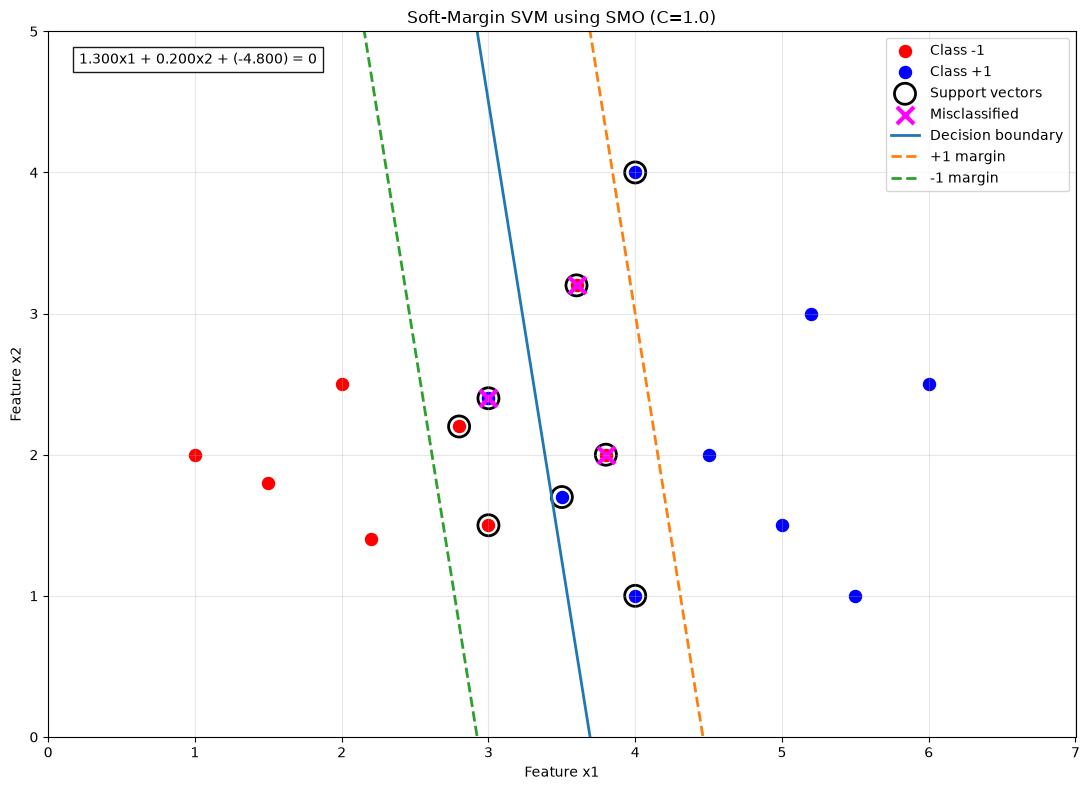

In [48]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: Create 17 overlapping data points
# ==========================================

X = np.array([
    [1.0, 2.0],
    [1.5, 1.8],
    [2.0, 2.5],
    [2.2, 1.4],
    [2.8, 2.2],
    [3.0, 1.5],
    [3.6, 3.2],   # Negative-class outlier
    [3.8, 2.0],

    [4.0, 4.0],
    [4.0, 1.0],
    [4.5, 2.0],
    [5.0, 1.5],
    [5.2, 3.0],
    [5.5, 1.0],
    [6.0, 2.5],
    [3.0, 2.4],   # Positive-class outlier
    [3.5, 1.7]    # Positive-class point near negatives
])

y = np.array([-1.0] * 8 + [1.0] * 9)

# Soft-margin penalty
C = 1.0

# ==========================================
# STEP 2: Implement SMO
# ==========================================


def soft_margin_smo(X, y, C=1.0, tol=1e-4,
                    eps=1e-7, max_passes=20,
                    max_iter=100000):

    n = len(X)
    K = X @ X.T
    alpha = np.zeros(n)
    b = 0.0
    iterations = 0
    passes = 0

    def errors():
        return (alpha * y) @ K + b - y

    while passes < max_passes and iterations < max_iter:
        changed = 0
        E = errors()

        for i in range(n):
            Ei = E[i]
            ri = y[i] * Ei

            # KKT violation check
            if not (
                (ri < -tol and alpha[i] < C - eps)
                or
                (ri > tol and alpha[i] > eps)
            ):
                continue

            # Try all other points, largest error difference first
            candidates = sorted(
                (j for j in range(n) if j != i),
                key=lambda j: abs(Ei - E[j]),
                reverse=True
            )

            for j in candidates:
                Ej = E[j]
                ai_old, aj_old = alpha[i], alpha[j]

                # Feasible bounds
                if y[i] != y[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = min(C, C + aj_old - ai_old)
                else:
                    L = max(0.0, ai_old + aj_old - C)
                    H = min(C, ai_old + aj_old)

                if H - L < eps:
                    continue

                eta = K[i, i] + K[j, j] - 2 * K[i, j]
                if eta <= eps:
                    continue

                aj_new = aj_old + y[j] * (Ei - Ej) / eta
                aj_new = np.clip(aj_new, L, H)

                if abs(aj_new - aj_old) < eps:
                    continue

                ai_new = ai_old + y[i] * y[j] * (
                    aj_old - aj_new
                )

                b1 = (
                    b - Ei
                    - y[i] * (ai_new - ai_old) * K[i, i]
                    - y[j] * (aj_new - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (ai_new - ai_old) * K[i, j]
                    - y[j] * (aj_new - aj_old) * K[j, j]
                )

                if eps < ai_new < C - eps:
                    b = b1
                elif eps < aj_new < C - eps:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                alpha[i] = ai_new
                alpha[j] = aj_new

                changed += 1
                E = errors()
                break

        iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    w = (alpha * y) @ X
    return w, b, alpha, iterations


# ==========================================
# STEP 3: Train the model
# ==========================================

w, b, alpha, iterations = soft_margin_smo(X, y, C=C)

# Decision function
scores = X @ w + b
predictions = np.where(scores >= 0, 1.0, -1.0)

# Functional margin for each point
functional_margin = y * scores

# Support vectors: alpha > 0
support_mask = alpha > 1e-5

# Points inside or on the margin
margin_mask = functional_margin <= 1 + 1e-4

# Incorrectly classified points
misclassified_mask = functional_margin < -1e-4

print("Iterations:", iterations)
print("C:", C)
print("\nWeight vector:", w)
print("Bias:", b)

print("\nLearned hyperplane:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + ({b:.4f}) = 0")

print("\nMargin width:", 2 / np.linalg.norm(w))
print("Number of support vectors:", np.sum(support_mask))
print("Number inside/on margin:", np.sum(margin_mask))
print("Number misclassified:", np.sum(misclassified_mask))

print("\nSupport vector details:")
for i in range(len(X)):
    if support_mask[i]:
        print(
            f"Point={X[i]}, label={int(y[i])}, "
            f"alpha={alpha[i]:.4f}, "
            f"y*f(x)={functional_margin[i]:.4f}"
        )

print("\nMisclassified points:")
for i in np.where(misclassified_mask)[0]:
    print(
        f"Point={X[i]}, true={int(y[i])}, "
        f"predicted={int(predictions[i])}"
    )

print("\nEquality constraint sum(alpha*y):",
      np.sum(alpha * y))

print("All alpha values within [0, C]:",
      np.all(alpha >= -1e-6) and np.all(alpha <= C + 1e-6))


print("\nKKT diagnostic:")

for i in range(len(X)):
    print(
        f"i={i:2d}, point={X[i]}, "
        f"y*f(x)={functional_margin[i]:7.3f}, "
        f"alpha={alpha[i]:7.4f}"
    )


# ==========================================
# STEP 4: Plot the learned model
# ==========================================

plt.figure(figsize=(11, 8))

plt.scatter(
    X[y == -1, 0], X[y == -1, 1],
    color="red", s=75, label="Class -1"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", s=75, label="Class +1"
)

# Circle all support vectors
plt.scatter(
    X[support_mask, 0], X[support_mask, 1],
    s=230, facecolors="none", edgecolors="black",
    linewidths=2, label="Support vectors"
)

# Crosses indicate misclassified points
if np.any(misclassified_mask):
    plt.scatter(
        X[misclassified_mask, 0],
        X[misclassified_mask, 1],
        marker="x", color="magenta", s=150,
        linewidths=3, label="Misclassified"
    )

# Draw decision boundary and margin lines
x_line = np.linspace(0, 7, 300)

for level, style, label in [
    (0, "-", "Decision boundary"),
    (1, "--", "+1 margin"),
    (-1, "--", "-1 margin")
]:
    if abs(w[1]) > 1e-8:
        y_line = (level - b - w[0] * x_line) / w[1]
        plt.plot(
            x_line, y_line,
            linestyle=style, linewidth=2,
            label=label
        )
    elif abs(w[0]) > 1e-8:
        x_value = (level - b) / w[0]
        plt.axvline(
            x_value, linestyle=style,
            linewidth=2, label=label
        )

equation = (
    f"{w[0]:.3f}x1 + {w[1]:.3f}x2 "
    f"+ ({b:.3f}) = 0"
)

plt.text(
    0.03, 0.97, equation,
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.9)
)

plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.title(f"Soft-Margin SVM using SMO (C={C})")
plt.xlim(0, 7)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from time import time

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, 
                                                    random_state=random_state)

svm = HardMarginSVM(lambda_param=.001, epochs=5000)

st = time()
svm.fit(X_train, y_train)
et = time()
elapsed_time = et - st
print(f"Model fitting took: {elapsed_time} seconds")

pred = svm.predict(X_test)
accuracy_score(y_test, pred)

Model fitting took: 0.08324766159057617 seconds


1.0

Iterations: 11621
Alpha values:
[0.       0.       0.       0.       0.       2.       0.       0.
 0.333333 1.666667 0.       0.       0.       0.       0.       0.
 0.      ]

Weight vector w: [1.99999995e+00 6.54721521e-09]
Bias b: -6.999999848660363

Hyperplane equation:
2.0000*x1 + 0.0000*x2 + (-7.0000) = 0
Margin width: 1.0000000225716281

Equality constraint sum(alpha*y): 0.0
Minimum alpha: 0.0
Minimum functional margin: 0.9999999742693069
All points satisfy hard margin: True

Support vectors:
Point: [3.  1.5] Class: -1 Alpha: 2.0 Margin: 1.0
Point: [4. 4.] Class: 1 Alpha: 0.333333 Margin: 1.0
Point: [4. 1.] Class: 1 Alpha: 1.666667 Margin: 1.0


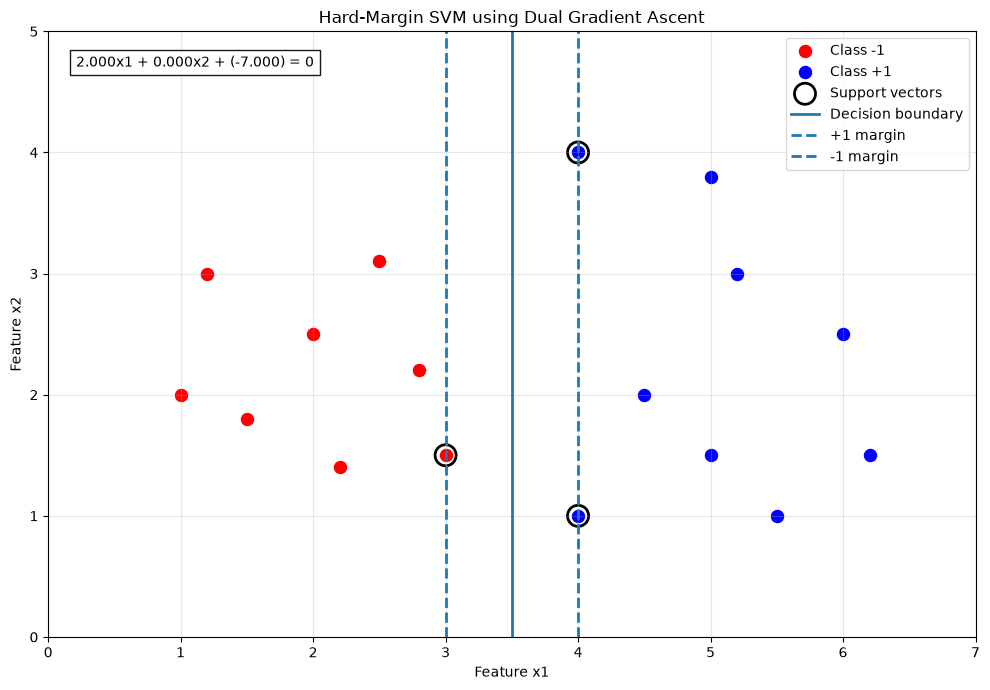

In [73]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: Create 17 linearly separable points
# ==========================================

X = np.array([
    [1.0, 2.0],
    [1.5, 1.8],
    [2.0, 2.5],
    [2.2, 1.4],
    [2.8, 2.2],
    [3.0, 1.5],
    [1.2, 3.0],
    [2.5, 3.1],

    [4.0, 4.0],
    [4.0, 1.0],
    [4.5, 2.0],
    [5.0, 1.5],
    [5.2, 3.0],
    [5.5, 1.0],
    [6.0, 2.5],
    [6.2, 1.5],
    [5.0, 3.8]
], dtype=float)

y = np.array([-1.0] * 8 + [1.0] * 9)

# ==========================================
# STEP 2: Build the dual objective matrix
# ==========================================

n = len(X)

# H[i,j] = yi * yj * (Xi dot Xj)
K = X @ X.T
H = np.outer(y, y) * K

# Gradient of dual objective:
# gradient = ones - H @ alpha

# ==========================================
# STEP 3: Project alpha onto feasible region
# ==========================================

def project_alpha(v, y):
    """
    Project v onto:
        alpha >= 0
        sum(alpha * y) = 0

    The solution has the form:
        alpha[i] = max(v[i] - lam*y[i], 0)

    Find lam using bisection.
    """

    def get_alpha(lam):
        return np.maximum(v - lam * y, 0.0)

    def constraint(lam):
        return np.sum(y * get_alpha(lam))

    # Find a bracket for the root
    left = -1.0
    right = 1.0

    while constraint(left) < 0:
        left *= 2.0

    while constraint(right) > 0:
        right *= 2.0

    # Bisection to satisfy sum(alpha*y) = 0
    for _ in range(100):
        mid = (left + right) / 2.0

        if constraint(mid) > 0:
            left = mid
        else:
            right = mid

    return get_alpha((left + right) / 2.0)


# ==========================================
# STEP 4: Gradient ascent on dual objective
# ==========================================

alpha = np.zeros(n)

# Stable step size based on largest eigenvalue of H
largest_eigenvalue = np.linalg.eigvalsh(H)[-1]
learning_rate = 1.0 / largest_eigenvalue

max_iterations = 200000
tolerance = 1e-10

for iteration in range(max_iterations):

    # Gradient of dual objective
    gradient = np.ones(n) - H @ alpha

    # Gradient ascent step
    alpha_new = alpha + learning_rate * gradient

    # Project back to feasible alpha values
    alpha_new = project_alpha(alpha_new, y)

    # Stop when alpha values have converged
    change = np.linalg.norm(alpha_new - alpha)
    alpha = alpha_new

    if change < tolerance:
        break

print("Iterations:", iteration + 1)
print("Alpha values:")
print(np.round(alpha, 6))

# ==========================================
# STEP 5: Recover w and b
# ==========================================

# w = sum(alpha_i * y_i * X_i)
w = (alpha * y) @ X

# Support vectors have positive alpha
support_mask = alpha > 1e-5

# Calculate bias using support vectors
# At a support vector: y_i * (w.X_i + b) = 1
# Therefore: b = y_i - w.X_i
b_values = y[support_mask] - X[support_mask] @ w
b = np.mean(b_values)

print("\nWeight vector w:", w)
print("Bias b:", b)

print("\nHyperplane equation:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + ({b:.4f}) = 0")

print("Margin width:", 2.0 / np.linalg.norm(w))

# ==========================================
# STEP 6: Check constraints
# ==========================================

scores = X @ w + b
functional_margin = y * scores

print("\nEquality constraint sum(alpha*y):",
      np.sum(alpha * y))

print("Minimum alpha:", np.min(alpha))
print("Minimum functional margin:",
      np.min(functional_margin))

print("All points satisfy hard margin:",
      np.all(functional_margin >= 1.0 - 1e-4))

print("\nSupport vectors:")
for i in range(n):
    if support_mask[i]:
        print(
            "Point:", X[i],
            "Class:", int(y[i]),
            "Alpha:", round(alpha[i], 6),
            "Margin:", round(functional_margin[i], 6)
        )

# ==========================================
# STEP 7: Visualize the hyperplane and margins
# ==========================================

plt.figure(figsize=(10, 7))

plt.scatter(
    X[y == -1, 0], X[y == -1, 1],
    color="red", s=75, label="Class -1"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", s=75, label="Class +1"
)

# Circle support vectors
plt.scatter(
    X[support_mask, 0], X[support_mask, 1],
    s=230, facecolors="none",
    edgecolors="black", linewidths=2,
    label="Support vectors"
)

x_line = np.linspace(0, 7, 300)

# Draw decision boundary and margins
for level, style, label in [
    (0, "-", "Decision boundary"),
    (1, "--", "+1 margin"),
    (-1, "--", "-1 margin")
]:
    if abs(w[1]) > 1e-8:
        y_line = (level - b - w[0] * x_line) / w[1]

        plt.plot(
            x_line, y_line,
            linestyle=style, linewidth=2,
            label=label
        )
    else:
        x_value = (level - b) / w[0]

        plt.axvline(
            x_value, linestyle=style,
            linewidth=2, label=label
        )

# Display learned equation
equation = (
    f"{w[0]:.3f}x1 + {w[1]:.3f}x2 "
    f"+ ({b:.3f}) = 0"
)

plt.text(
    0.03, 0.96, equation,
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.9)
)

plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.title("Hard-Margin SVM using Dual Gradient Ascent")
plt.xlim(0, 7)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Training epochs: 56
C: 1.0
Weights w: [0.6666666666666667, -6.38378239159465e-16]
Bias b: -2.7755575615628914e-16
Support vector indices: [3, 6, 7, 8, 9, 10, 14, 17, 18, 19, 20, 21]
Number of support vectors: 12
Training accuracy: 81.82 %
Misclassified indices: [6, 9, 17, 20]


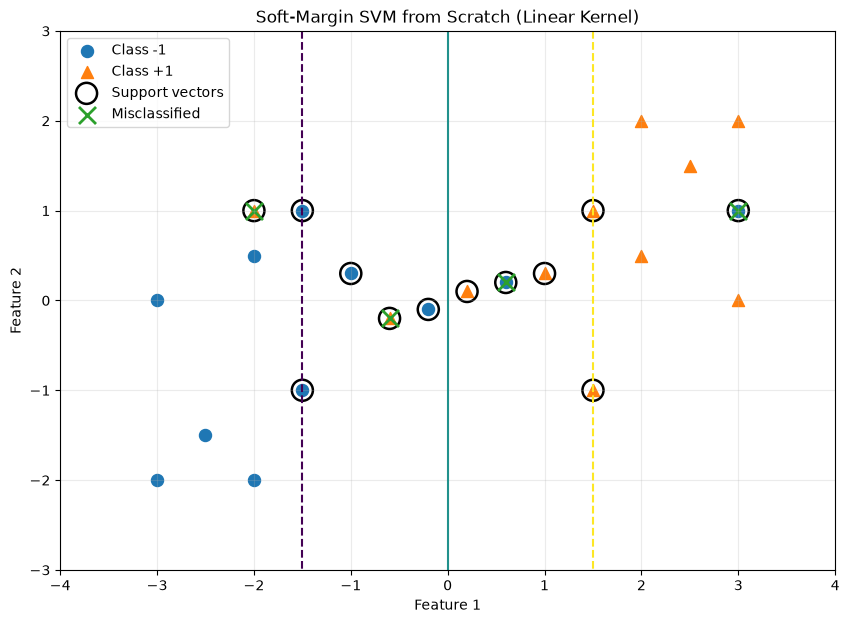

In [87]:

import random
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. DATASET: 10 negative and 10 positive points
# --------------------------------------------------

X = [
    [-3, -2],
    [-2.5, -1.5],
    [-2, -2],
    [-1.5, -1],
    [-3, 0],
    [-2, 0.5],
    [3, 1],
    [-1.5, 1],
    [-1, 0.3],
    [0.6, 0.2],       # Overlapping point
    [-0.2, -0.1],      # Near the boundary

    [3, 2],
    [2.5, 1.5],
    [2, 2],
    [1.5, 1],
    [3, 0],
    [2, 0.5],
    [-2, 1],
    [1.5, -1],
    [1, 0.3],
    [-0.6, -0.2],     # Overlapping point
    [0.2, 0.1]        # Near the boundary
]

y = [-1] * 11 + [1] * 11
# X = np.array([
#     [1.0, 2.0],
#     [1.5, 1.8],
#     [2.0, 2.5],
#     [2.2, 1.4],
#     [2.8, 2.2],
#     [3.0, 1.5],
#     [3.6, 3.2],   # Negative-class outlier
#     [3.8, 2.0],

#     [4.0, 4.0],
#     [4.0, 1.0],
#     [4.5, 2.0],
#     [5.0, 1.5],
#     [5.2, 3.0],
#     [5.5, 1.0],
#     [6.0, 2.5],
#     [3.0, 2.4],   # Positive-class outlier
#     [3.5, 1.7]    # Positive-class point near negatives
# ])

# y = np.array([-1.0] * 8 + [1.0] * 9)

# --------------------------------------------------
# 2. HELPER FUNCTIONS
# --------------------------------------------------

def dot_product(a, b):
    total = 0.0

    for i in range(len(a)):
        total += a[i] * b[i]

    return total


def create_kernel_matrix(X):
    n = len(X)
    K = [[0.0] * n for _ in range(n)]

    for i in range(n):
        for j in range(n):
            K[i][j] = dot_product(X[i], X[j])

    return K


def calculate_score(i, y, alphas, b, K):
    score = b

    for j in range(len(y)):
        score += alphas[j] * y[j] * K[j][i]

    return score


def calculate_error(i, y, alphas, b, K):
    return calculate_score(i, y, alphas, b, K) - y[i]


def clip(value, lower, upper):
    if value < lower:
        return lower
    if value > upper:
        return upper
    return value


# --------------------------------------------------
# 3. SOFT-MARGIN SVM USING SMO
# --------------------------------------------------

def train_svm(X, y, C=1.0, tolerance=0.001,
              max_passes=20, max_epochs=1000, seed=42):

    n = len(X)
    K = create_kernel_matrix(X)

    alphas = [0.0] * n
    b = 0.0

    rng = random.Random(seed)
    passes = 0
    epoch = 0

    while passes < max_passes and epoch < max_epochs:
        changes = 0

        for i in range(n):
            E1 = calculate_error(i, y, alphas, b, K)
            r1 = y[i] * E1

            # Check whether this point violates KKT conditions
            if not (
                (r1 < -tolerance and alphas[i] < C - 1e-8)
                or
                (r1 > tolerance and alphas[i] > 1e-8)
            ):
                continue

            # Select a different point
            j = rng.randrange(n - 1)

            if j >= i:
                j += 1

            E2 = calculate_error(j, y, alphas, b, K)

            a1_old = alphas[i]
            a2_old = alphas[j]

            y1 = y[i]
            y2 = y[j]

            # Calculate valid bounds for alpha2
            if y1 != y2:
                L = max(0.0, a2_old - a1_old)
                H = min(C, C + a2_old - a1_old)
            else:
                L = max(0.0, a1_old + a2_old - C)
                H = min(C, a1_old + a2_old)

            if H - L < 1e-12:
                continue

            # Negative eta convention for SMO
            eta = (
                2 * K[i][j]
                - K[i][i]
                - K[j][j]
            )

            if eta >= -1e-12:
                # This basic implementation skips degenerate pairs
                continue

            # Proposed new alpha2
            a2_new = (
                a2_old
                - y2 * (E1 - E2) / eta
            )

            # Keep alpha2 inside its valid bounds
            a2_new = clip(a2_new, L, H)

            if abs(a2_new - a2_old) < 1e-6:
                continue

            # Calculate alpha1 from the equality constraint
            a1_new = (
                a1_old
                + y1 * y2 * (a2_old - a2_new)
            )

            # Calculate the two possible bias values
            delta1 = a1_new - a1_old
            delta2 = a2_new - a2_old

            b1 = (
                b - E1
                - y1 * delta1 * K[i][i]
                - y2 * delta2 * K[i][j]
            )

            b2 = (
                b - E2
                - y1 * delta1 * K[i][j]
                - y2 * delta2 * K[j][j]
            )

            # Choose the bias using the updated alphas
            if 1e-8 < a1_new < C - 1e-8:
                b = b1
            elif 1e-8 < a2_new < C - 1e-8:
                b = b2
            else:
                b = (b1 + b2) / 2.0

            alphas[i] = a1_new
            alphas[j] = a2_new

            changes += 1

        epoch += 1

        if changes == 0:
            passes += 1
        else:
            passes = 0

    return alphas, b, K, epoch


# --------------------------------------------------
# 4. TRAIN THE MODEL
# --------------------------------------------------

C = 1.0

alphas, b, K, epochs = train_svm(
    X, y,
    C=C,
    tolerance=0.001,
    max_passes=20,
    max_epochs=1000
)

# Calculate w for the linear decision boundary
w = [0.0, 0.0]

for i in range(len(X)):
    for j in range(2):
        w[j] += alphas[i] * y[i] * X[i][j]

support_vectors = [
    i for i in range(len(X))
    if alphas[i] > 1e-5
]

print("Training epochs:", epochs)
print("C:", C)
print("Weights w:", w)
print("Bias b:", b)
print("Support vector indices:", support_vectors)
print("Number of support vectors:", len(support_vectors))


# --------------------------------------------------
# 5. PREDICT AND EVALUATE
# --------------------------------------------------

def predict(point, X, y, alphas, b):
    score = b

    for i in range(len(X)):
        score += (
            alphas[i]
            * y[i]
            * dot_product(X[i], point)
        )

    return 1 if score >= 0 else -1


correct = 0
misclassified = []

for i in range(len(X)):
    prediction = predict(X[i], X, y, alphas, b)

    if prediction == y[i]:
        correct += 1
    else:
        misclassified.append(i)

accuracy = 100 * correct / len(X)

print("Training accuracy:", round(accuracy, 2), "%")
print("Misclassified indices:", misclassified)


# --------------------------------------------------
# 6. VISUALIZE DECISION BOUNDARY AND MARGINS
# --------------------------------------------------

plt.figure(figsize=(10, 7))

# Plot the two classes
negative = [X[i] for i in range(len(X)) if y[i] == -1]
positive = [X[i] for i in range(len(X)) if y[i] == 1]

plt.scatter(
    [p[0] for p in negative],
    [p[1] for p in negative],
    marker="o", s=75, label="Class -1"
)

plt.scatter(
    [p[0] for p in positive],
    [p[1] for p in positive],
    marker="^", s=75, label="Class +1"
)

# Highlight support vectors
plt.scatter(
    [X[i][0] for i in support_vectors],
    [X[i][1] for i in support_vectors],
    s=230, facecolors="none", edgecolors="black",
    linewidths=1.8, label="Support vectors"
)

# Highlight misclassified training points
if misclassified:
    plt.scatter(
        [X[i][0] for i in misclassified],
        [X[i][1] for i in misclassified],
        marker="x", s=150, linewidths=2,
        label="Misclassified"
    )

# Create a grid to visualize the model scores
x_values = [
    -4 + i * 0.1 for i in range(81)
]
y_values = [
    -3 + i * 0.1 for i in range(61)
]

Z = []

for yy in y_values:
    row = []

    for xx in x_values:
        point = [xx, yy]

        score = b

        for i in range(len(X)):
            score += (
                alphas[i]
                * y[i]
                * dot_product(X[i], point)
            )

        row.append(score)

    Z.append(row)

# Decision boundary: score = 0
# Margins: score = -1 and score = +1
plt.contour(
    x_values, y_values, Z,
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"]
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Soft-Margin SVM from Scratch (Linear Kernel)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()
